# Lab 3 — CarRacing-v3: improving the baseline DQN

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dqn_car_racing import make_env, QNetwork, device
from test_car_racing import evaluate_checkpoint

RUNS = ["baseline", "double", "dueling", "eps_step", "final"]
COLORS = {"baseline": "#eb6834", "double": "#1baf7a", "dueling": "#d6452a",
          "eps_step": "#8a5cd6", "final": "#2a78d6", "final_long": "#0f8a8a"}
scores = {n: np.load(f"runs/ablations/{n}_scores.npy") for n in RUNS}
scores["final_long"] = np.load("runs/final_long/final_long_scores.npy")

def moving_avg(x, w=100):
    return np.array([x[max(0, i - w + 1):i + 1].mean() for i in range(len(x))])

## 1. What was changed and why

| Run | Change vs baseline | Why it should help |
|---|---|---|
| `double` | **Double DQN**: the online net picks the next action, the target net evaluates it | `max` over noisy Q-values is biased upward (overestimation). Splitting "choose" and "evaluate" removes most of the bias, so the agent does not chase actions that only look good because of noise. |
| `dueling` | **Dueling head**: `Q = V(s) + A(s,a) − mean A` | On a straight road most actions are almost equal. The net learns how good the state is (V) from every action's update, and only the small differences between actions (A) need extra data. |
| `eps_step` | **ε decay per env step** (1.0 → 0.05 linearly over 200k steps) + 10k warm-up steps before learning | The baseline decays ε per finished episode, so it explores heavily for ~600 episodes. Per-step decay explores for ~200 episodes and leaves more of training for driving well. The warm-up fills the buffer with varied data before the first updates. |
| `final` | all three | |
| `final_long` | `final` + 2000 episodes, ε 0.05 → 0.01, checkpoint picked by a greedy test of snapshots | The `final` curve was still rising at episode 1000. A lower ε makes training data closer to the greedy test, and picking by a greedy test avoids checkpoints that only looked good with random actions. |

## 2. Re-testing locally (50 greedy episodes)

- The provided baseline checkpoint, with `evaluate_checkpoint` from `test_car_racing.py` and `dueling=False` (random tracks, so the Mean moves by about ±15 between runs).

In [2]:
r = evaluate_checkpoint("checkpoints/checkpoint_CarRacing-v3_best.pth", 50, dueling=False)
baseline_local = {"Mean": r.mean(), "Std": r.std(), "Min": r.min(), "Max": r.max()}
baseline_local

{'Mean': np.float64(809.2688895409983),
 'Std': np.float64(150.2357198764078),
 'Min': np.float64(358.68945868944684),
 'Max': np.float64(927.5999999999946)}

- The final checkpoint, with the **original** `test_car_racing.py`.

In [3]:
!{sys.executable} test_car_racing.py checkpoints/final_CarRacing-v3.pth 50 | tail -5

Episodes : 50
Mean     : 899.7
Std      : 19.1
Min      : 856.5
Max      : 924.8


## 3. Results table (50 test episodes each)

In [4]:
results = pd.read_csv("runs/ablations/results.csv", index_col=0)  # Kaggle tests of each run
table = pd.concat([
    pd.DataFrame({"baseline checkpoint (task)": {"Mean": 840.6, "Std": 103.2, "Min": 470.4, "Max": 912.7},
                  "baseline checkpoint (re-test here)": baseline_local}).T,
    results.loc[RUNS].rename(index=lambda n: f"{n} (1000 ep)"),
    pd.DataFrame({"final_long, snapshot ep1100 (Kaggle)": {"Mean": 895.2, "Std": 26.5, "Min": 796.3, "Max": 930.2},
                  "final_long, snapshot ep1100 (re-test here)": {"Mean": 899.7, "Std": 19.1, "Min": 856.5, "Max": 924.8}}).T,
])
table.round(1)

,Mean,Std,Min,Max
baseline checkpoint (task),840.6,103.2,470.4,912.7
baseline checkpoint (re-test here),809.3,150.2,358.7,927.6
baseline (1000 ep),718.9,198.7,330.7,930.0
double (1000 ep),851.0,82.5,545.8,924.2
dueling (1000 ep),800.2,154.3,242.6,929.6
eps_step (1000 ep),624.8,213.1,227.3,929.2
final (1000 ep),894.8,43.0,697.5,926.7
"final_long, snapshot ep1100 (Kaggle)",895.2,26.5,796.3,930.2
"final_long, snapshot ep1100 (re-test here)",899.7,19.1,856.5,924.8


- **final_long (895.2 on Kaggle, 899.7 here)** and **final (894.8)** are clearly above the baseline (840.6).
- The provided baseline checkpoint scored only **809.3** in our re-test. The final checkpoint is stable across tests (895.2 vs 899.7) because it has almost no bad episodes.
- `Max` is ~925–930 for every run: on an easy track every agent drives almost perfectly
- The final model is the most reliable: Min 796–857 vs 359–470 for the baseline checkpoint, Std 19–27 vs 103–150.
- Our own baseline run (718.9) is worse than the provided checkpoint (840.6) with the same code: one training run is a noisy measurement.

## 4. Learning curves: baseline vs final

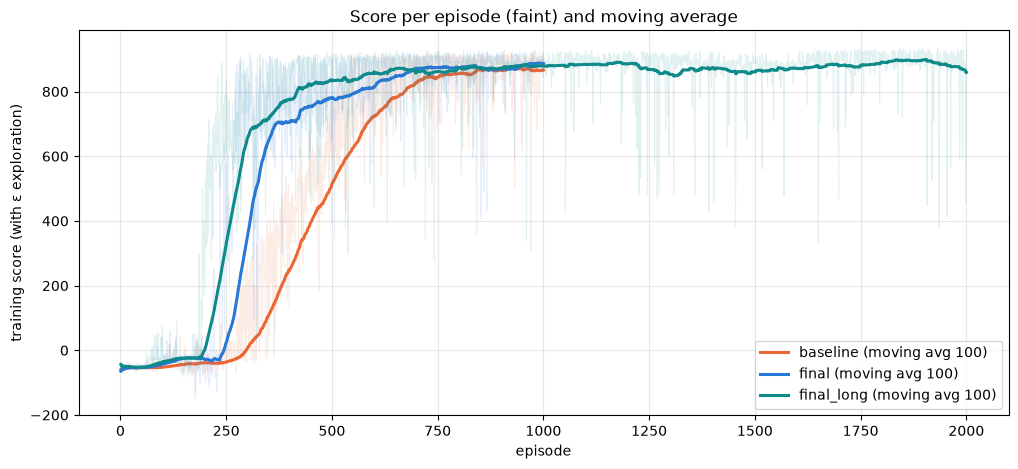

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
for n in ["baseline", "final", "final_long"]:
    s = scores[n]
    ax.plot(np.arange(1, len(s) + 1), s, color=COLORS[n], alpha=0.12, lw=0.8)
    ax.plot(np.arange(1, len(s) + 1), moving_avg(s), color=COLORS[n], lw=2.2, label=f"{n} (moving avg 100)")
ax.set(xlabel="episode", ylabel="training score (with ε exploration)", title="Score per episode (faint) and moving average")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.show()

- Final reaches a moving average of 700 at episode **368**, the baseline at **582**: about 1.6× faster.
- All curves end at a similar training level (~870–890): with 1000 episodes the gain is mainly **speed** and how **reliable** the greedy policy is, not the training score.
- `final_long` gets to the same level and stays there; the extra 1000 episodes do not raise it.

## 5. Ablation curves

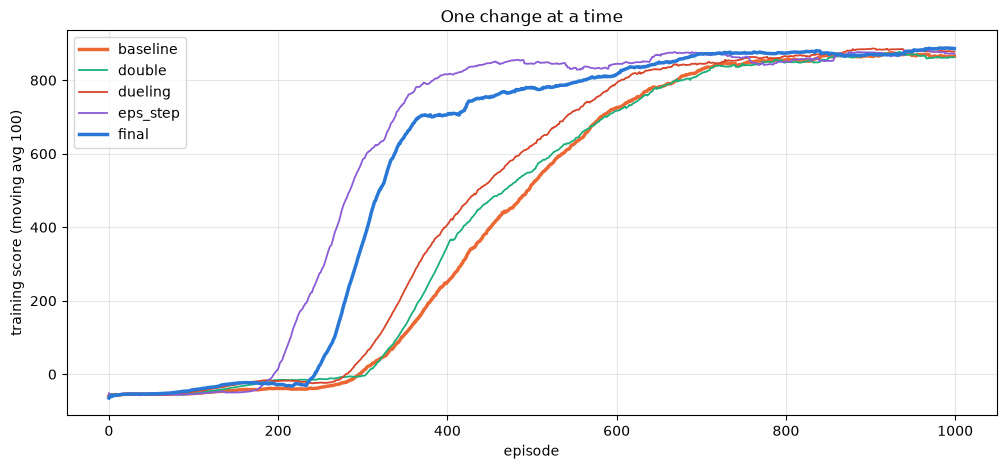

,MA ≥ 700 at episode,MA ≥ 800 at episode,best training MA,test Mean
baseline,582.0,673.0,874.6,718.9
double,587.0,672.0,877.3,851.0
dueling,542.0,606.0,886.4,800.2
eps_step,340.0,385.0,884.4,624.8
final,368.0,562.0,887.8,894.8


In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for n in RUNS:
    ax.plot(moving_avg(scores[n]), color=COLORS[n], lw=2.5 if n in ("baseline", "final") else 1.3, label=n)
ax.set(xlabel="episode", ylabel="training score (moving avg 100)", title="One change at a time")
ax.grid(alpha=0.3); ax.legend()
plt.show()

first = lambda ma, th: next(i + 1 for i, v in enumerate(ma) if i >= 99 and v >= th)
pd.DataFrame({n: {"MA ≥ 700 at episode": first(moving_avg(scores[n]), 700),
                  "MA ≥ 800 at episode": first(moving_avg(scores[n]), 800),
                  "best training MA": moving_avg(scores[n])[9:].max().round(1),
                  "test Mean": results.loc[n, "Mean"]} for n in RUNS}).T

- **eps_step** is by far the biggest speed-up: less time wasted on random driving.
- **dueling** gives a moderate speed-up (542).
- **double** does not learn faster, but its greedy test is much more stable. That fits: it fixes biased Q-values, not learning speed.
- **eps_step** has the best curve but the worst test (624.8). The curve and the checkpoint choice use the training score **with** 5% random actions, and those random actions can pull the car out of bad situations. The greedy policy can repeat the same mistake every time. In `final`, Double DQN's more reliable Q-values seem to fix this.

## 6. Longer final run: does the greedy policy keep improving

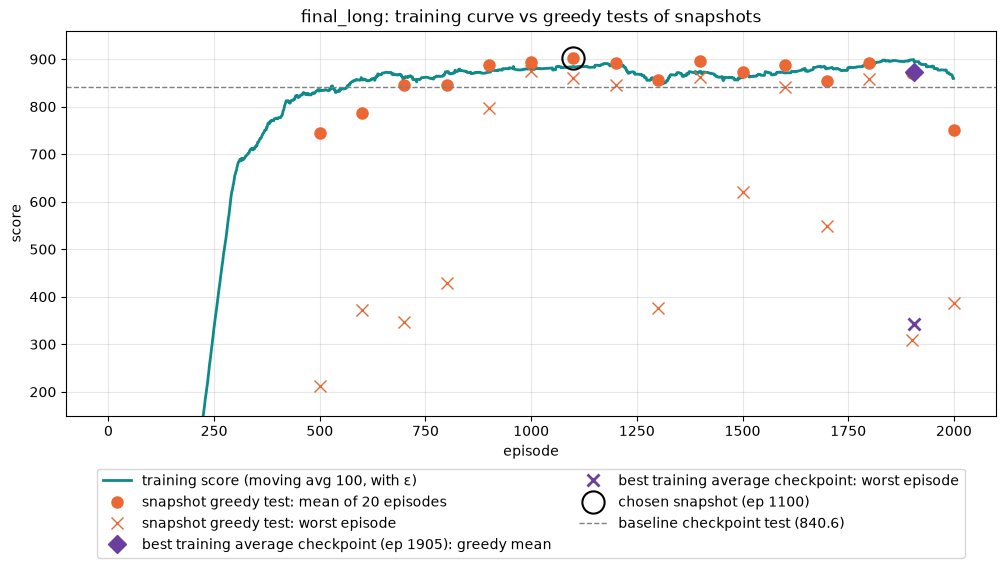

checkpoint with the best training average: greedy mean 872.7, worst 342.4


In [7]:
snap = pd.read_csv("runs/final_long/final_long_snapshots.csv", index_col=0)
best_train = snap.loc["final_long.pth"]
snap = snap.drop("final_long.pth")
snap_ep = [int(n.split("_ep")[1].split(".")[0]) for n in snap.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(moving_avg(scores["final_long"]), color=COLORS["final_long"], lw=2, label="training score (moving avg 100, with ε)")
ax.plot(snap_ep, snap["Mean"], "o", color="#eb6834", ms=8, label="snapshot greedy test: mean of 20 episodes")
ax.plot(snap_ep, snap["Min"], "x", color="#eb6834", ms=8, label="snapshot greedy test: worst episode")
# checkpoint saved at the highest training moving average (the usual "best" rule)
ma = moving_avg(scores["final_long"])
best_ep = ma[9:].argmax() + 10
ax.plot(best_ep, best_train["Mean"], "D", color="#6b3fa0", ms=9,
        label=f"best training average checkpoint (ep {best_ep}): greedy mean")
ax.plot(best_ep, best_train["Min"], "x", color="#6b3fa0", ms=9, mew=2, label="best training average checkpoint: worst episode")
chosen_ep = snap_ep[snap["Mean"].values.argmax()]
ax.plot(chosen_ep, snap["Mean"].max(), "o", ms=16, mfc="none", mec="black", mew=1.5,
        label=f"chosen snapshot (ep {chosen_ep})")
ax.axhline(840.6, color="gray", ls="--", lw=1, label="baseline checkpoint test (840.6)")
ax.set(xlabel="episode", ylabel="score", ylim=(150, 960), title="final_long: training curve vs greedy tests of snapshots")
ax.grid(alpha=0.3); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.show()
print(f"checkpoint with the best training average: greedy mean {best_train['Mean']}, worst {best_train['Min']}")

- The greedy policy peaks at episodes **900–1200**, and after that it only **oscillates**: some snapshots crash, and the last one is bad.
- Training longer did not help: 1000 episodes were already enough for this setup.
- The checkpoint with the best **training** average (899) scores only 872.7 greedily, with a 342 crash. A score measured with random actions is a poor way to pick a checkpoint.
- What helped is **picking by a greedy test**: ep1100 got 902.7 on its 20 selection episodes and 895.2 on 50 new ones with the official script (slightly lower, because it was chosen on the first 20).

## 7. The final agent driving

reward 919.0, 810 frames


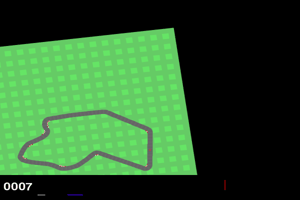

In [8]:
from PIL import Image as PILImage
from IPython.display import Image

policy = QNetwork(a_size=5).to(device)
policy.load_state_dict(__import__("torch").load("checkpoints/final_CarRacing-v3.pth", map_location=device))
policy.eval()
env = make_env(render_mode="rgb_array")
state, _ = env.reset(seed=1)
frames, total, done = [], 0.0, False
while not done:
    state, reward, terminated, truncated, _ = env.step(policy.act(state))
    done = terminated or truncated
    total += reward
    if len(frames) < 2000:
        frames.append(env.render())
env.close()
print(f"reward {total:.1f}, {len(frames)} frames")
gif = [PILImage.fromarray(f).resize((300, 200)) for f in frames[::4]]
gif[0].save("final_episode.gif", save_all=True, append_images=gif[1:], duration=50, loop=0)
Image(filename="final_episode.gif")

## 8. Conclusion

- **Result**: the final checkpoint `checkpoints/final_CarRacing-v3.pth` gets **Mean 895.2** on Kaggle and **899.7** here (Std 19–27, Min 796–857) with the original `test_car_racing.py`, vs **840.6** claimed / **809.3** re-tested (Std 103–150, Min 359–470) for the baseline.
- **Which change mattered**:
  - **ε decay per step**: the biggest speed-up; the agent stops driving randomly much earlier.
  - **Dueling**: a moderate speed-up.
  - **Double DQN**: does not learn faster, but gives a more stable greedy policy.
  - Together they learn ~1.6× faster than the baseline and crash much less in the test.
- **The gain is in reliability, not in a better lap.** All agents score ~930 on easy tracks; the improvement is fewer disaster episodes.
- **Training longer did not help**: the greedy policy stops improving after ~1000 episodes and then oscillates. Picking the checkpoint by a greedy test (not by the training average with random actions) is what gave the most stable model.
- **Limitations**: one training run per config, and test tracks are random, so the single-change rows are noisy (our own baseline run gave 718.9, the provided checkpoint 840.6).